# Oral Disease Image Classification

A complete project notebook covering duplicate-aware data preparation, a custom CNN, three pretrained models, hyperparameter tuning, comparative evaluation, and a Gradio deployment app.

The final test split uses one representative per near-duplicate group. Training keeps the remaining variants within their assigned groups.

## Clinical scope

The model predicts one image-level category from the six labels in this dataset. Oral findings can coexist, and some conditions need clinical examination or imaging. Present the output as an image-classification result for review.

## 1. Load the dataset
Attach the Oral Diseases dataset to this Kaggle notebook. The cell checks the expected folder paths and reports the image counts.

In [1]:
import os, sys, math, time, random, hashlib, itertools, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings("ignore")
T0 = time.time()

SEED = 42
IMG_SIZE = 256
BATCH_SIZE = 32
GROUP_THRESHOLD = 6
PRETRAINED = True
MAX_SAMPLES_PER_EPOCH = 6000
CUTMIX_PROB = 0.3
EPOCHS = {
    "resnet50": 9,
    "efficientnet_b0": 14,
    "convnext_tiny": 12,
    "custom_cnn": 25,
}
NUM_THREADS = min(8, (os.cpu_count() or 2) * 2)

WORKING_DIR = Path("/kaggle/working") if Path("/kaggle").exists() else Path("./working")
WORKING_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(WORKING_DIR))

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

CUDA = torch.cuda.is_available()
device = torch.device("cuda" if CUDA else "cpu")
torch.backends.cudnn.benchmark = True
set_seed(SEED)
print("cuda:", CUDA, "|", torch.cuda.get_device_name(0) if CUDA else "CPU only (enable a GPU in Kaggle!)")

DATA_ROOT_OPTIONS = [
    Path("/kaggle/input/datasets/salmansajid05/oral-diseases"),
    Path("/kaggle/input/oral-diseases"),
]
DATA_ROOT = next((path for path in DATA_ROOT_OPTIONS if path.exists()), None)
if DATA_ROOT is None:
    raise FileNotFoundError("Attach the Oral Diseases dataset and verify its Kaggle input path.")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASS_FOLDERS = {
    "Calculus": DATA_ROOT / "Calculus" / "Calculus",
    "Caries": DATA_ROOT / "Data caries" / "Data caries" / "caries orignal data set" / "done",
    "Gingivitis": DATA_ROOT / "Gingivitis" / "Gingivitis",
    "Hypodontia": DATA_ROOT / "hypodontia" / "hypodontia",
    "Mouth_Ulcer": DATA_ROOT / "Mouth Ulcer" / "Mouth Ulcer" / "ulcer original dataset" / "ulcer original dataset",
    "Tooth_Discoloration": DATA_ROOT / "Tooth Discoloration" / "Tooth Discoloration " / "tooth discoloration original dataset" / "tooth discoloration original dataset",
}

records, missing = [], []
for label, folder in CLASS_FOLDERS.items():
    if not folder.exists():
        print("MISSING:", label, "->", folder)
        missing.append(label)
        continue
    files = sorted(p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    print(f"{label:<20}{len(files)}")
    records.extend((str(p), label) for p in files)

if missing:
    print("top-level folders found:", sorted(p.name for p in DATA_ROOT.iterdir()))
    raise FileNotFoundError(f"Fix CLASS_FOLDERS for: {missing}")
print("total images:", len(records))

cuda: True | Tesla T4
Calculus            1296
Caries              219
Gingivitis          2349
Hypodontia          1251
Mouth_Ulcer         265
Tooth_Discoloration 183
total images: 5563


## 2. Detect exact and near-duplicate images
MD5 finds byte-identical files. Orientation-aware dHash compares grayscale structure across rotations and reflections and is tolerant of many ordinary brightness and contrast changes.

In [2]:
ORIENTATIONS = [
    None,
    Image.Transpose.FLIP_LEFT_RIGHT,
    Image.Transpose.FLIP_TOP_BOTTOM,
    Image.Transpose.ROTATE_90,
    Image.Transpose.ROTATE_180,
    Image.Transpose.ROTATE_270,
    Image.Transpose.TRANSPOSE,
    Image.Transpose.TRANSVERSE,
]

def md5_file(path):
    digest = hashlib.md5()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()

def dhash_int(gray):
    values = np.asarray(gray.resize((9, 8), Image.Resampling.LANCZOS), dtype=np.int16)
    bits = (values[:, 1:] > values[:, :-1]).reshape(-1)
    return int.from_bytes(np.packbits(bits).tobytes(), "big")

def hash_record(item):
    path, label = item
    try:
        with Image.open(path) as source:
            image = ImageOps.exif_transpose(source)
            width, height = image.size
            gray = image.convert("L").resize((72, 72), Image.Resampling.LANCZOS)
        variants = [dhash_int(gray if t is None else gray.transpose(t)) for t in ORIENTATIONS]
        return {"path": path, "label": label, "md5": md5_file(path), "variants": variants,
                "width": width, "height": height, "file_size": os.path.getsize(path)}
    except Exception as error:
        return {"path": path, "error": str(error)}

with ThreadPoolExecutor(NUM_THREADS) as pool:
    results = list(tqdm(pool.map(hash_record, records), total=len(records), desc="Hashing images"))

unreadable = [(r["path"], r["error"]) for r in results if "error" in r]
df = pd.DataFrame([r for r in results if "error" not in r])
if df.empty:
    raise RuntimeError("No readable images remain.")
print("readable:", len(df), "| unreadable:", len(unreadable))
print("exact duplicate files:", int(df["md5"].duplicated().sum()))
print("exact duplicate groups with multiple labels:", int((df.groupby("md5")["label"].nunique() > 1).sum()))

H = np.asarray(df["variants"].tolist(), dtype=np.uint64)
POP16 = np.asarray([bin(v).count("1") for v in range(65536)], dtype=np.uint8)

def popcount64(values):
    total = np.zeros(values.shape, dtype=np.int32)
    for shift in (0, 16, 32, 48):
        block = (values >> np.uint64(shift)) & np.uint64(0xFFFF)
        total += POP16[block.astype(np.int64)]
    return total

MAX_PAIR_DISTANCE = 6
assert GROUP_THRESHOLD <= MAX_PAIR_DISTANCE
H0 = H[:, 0]
PAIR_HISTOGRAM = np.zeros(11, dtype=np.int64)
pair_left, pair_right, pair_distance = [], [], []

for index in tqdm(range(len(H) - 1), desc="Comparing perceptual hashes"):
    distances = popcount64(np.bitwise_xor(H[index + 1:], H0[index])).min(axis=1)
    PAIR_HISTOGRAM += np.bincount(distances[distances <= 10], minlength=11)
    matches = np.flatnonzero(distances <= MAX_PAIR_DISTANCE)
    pair_left.extend([index] * len(matches))
    pair_right.extend((matches + index + 1).tolist())
    pair_distance.extend(distances[matches].tolist())

pair_left = np.asarray(pair_left, dtype=np.int32)
pair_right = np.asarray(pair_right, dtype=np.int32)
pair_distance = np.asarray(pair_distance, dtype=np.int16)

print("image pairs by minimum dHash distance:")
for distance, count in enumerate(PAIR_HISTOGRAM):
    print(distance, int(count))
print("pairs kept for grouping and review:", len(pair_distance))

Hashing images:   0%|          | 0/5563 [00:00<?, ?it/s]

readable: 5563 | unreadable: 0
exact duplicate files: 1664
exact duplicate groups with multiple labels: 392


Comparing perceptual hashes:   0%|          | 0/5562 [00:00<?, ?it/s]

image pairs by minimum dHash distance:
0 11811
1 4876
2 3527
3 3757
4 3181
5 2877
6 3033
7 4361
8 7210
9 12932
10 22033
pairs kept for grouping and review: 33062


## 3. Remove conflicting labels and split by image group
All variants at or below the selected dHash threshold are kept in the same split. Conflicting-label groups are removed. Training uses all remaining variants, while validation and test keep one representative per group.

In [3]:
from sklearn.model_selection import train_test_split

parent = np.arange(len(df), dtype=np.int32)

def find_root(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index

for left, right, distance in zip(pair_left, pair_right, pair_distance):
    if distance <= GROUP_THRESHOLD:
        root_left, root_right = find_root(int(left)), find_root(int(right))
        if root_left != root_right:
            parent[root_right] = root_left

cluster_ids = np.asarray([find_root(i) for i in range(len(df))])
all_images = df[["path", "label", "file_size"]].copy()
all_images["group_id"] = cluster_ids

labels_per_group = all_images.groupby("group_id")["label"].nunique()
conflict_groups = set(labels_per_group[labels_per_group > 1].index)
conflict_images = all_images[all_images["group_id"].isin(conflict_groups)]
eligible = all_images[~all_images["group_id"].isin(conflict_groups)].copy()

group_representatives = (
    eligible.sort_values(["file_size", "path"], ascending=[False, True])
    .drop_duplicates("group_id")
    .reset_index(drop=True)
)
CLASSES = sorted(group_representatives["label"].unique())
CLASS_TO_INDEX = {label: i for i, label in enumerate(CLASSES)}

trainval_groups, test_groups = train_test_split(
    group_representatives, test_size=0.15, stratify=group_representatives["label"], random_state=SEED)
train_groups, val_groups = train_test_split(
    trainval_groups, test_size=0.1765, stratify=trainval_groups["label"], random_state=SEED + 1)

train_group_ids = set(train_groups["group_id"])
val_group_ids = set(val_groups["group_id"])
test_group_ids = set(test_groups["group_id"])

train = eligible[eligible["group_id"].isin(train_group_ids)].copy().reset_index(drop=True)
val = val_groups.copy().reset_index(drop=True)
test = test_groups.copy().reset_index(drop=True)

assert train_group_ids.isdisjoint(val_group_ids)
assert train_group_ids.isdisjoint(test_group_ids)
assert val_group_ids.isdisjoint(test_group_ids)
assert len(val) == val["group_id"].nunique() and len(test) == test["group_id"].nunique()
assert set(train["label"]) == set(val["label"]) == set(test["label"]) == set(CLASSES)

split_of_group = {g: "train" for g in train_group_ids}
split_of_group.update({g: "validation" for g in val_group_ids})
split_of_group.update({g: "test" for g in test_group_ids})
cross_split_pairs = [
    int(d) for l, r, d in zip(pair_left, pair_right, pair_distance)
    if split_of_group.get(int(cluster_ids[l])) and split_of_group.get(int(cluster_ids[r]))
    and split_of_group[int(cluster_ids[l])] != split_of_group[int(cluster_ids[r])]
]
assert not [d for d in cross_split_pairs if d <= GROUP_THRESHOLD]

print("conflicting groups removed:", len(conflict_groups))
print("images in conflicting groups removed:", len(conflict_images))
print("clean images retained:", len(eligible))
print("unique image groups:", len(group_representatives))
print("training images / groups:", len(train), len(train_group_ids))
print("validation groups:", len(val), "| test groups:", len(test))
print("cross-split dHash pairs left at distance > threshold (for visual review):", len(cross_split_pairs))
print("train classes:", train["label"].value_counts().sort_index().to_dict())
print("validation groups:", val["label"].value_counts().sort_index().to_dict())
print("test groups:", test["label"].value_counts().sort_index().to_dict())

train[["path", "label", "group_id"]].to_csv(WORKING_DIR / "train.csv", index=False)
val[["path", "label", "group_id"]].to_csv(WORKING_DIR / "validation.csv", index=False)
test[["path", "label", "group_id"]].to_csv(WORKING_DIR / "test.csv", index=False)

conflicting groups removed: 126
images in conflicting groups removed: 1966
clean images retained: 3597
unique image groups: 1402
training images / groups: 2452 980
validation groups: 211 | test groups: 211
cross-split dHash pairs left at distance > threshold (for visual review): 0
train classes: {'Calculus': 290, 'Caries': 143, 'Gingivitis': 910, 'Hypodontia': 811, 'Mouth_Ulcer': 184, 'Tooth_Discoloration': 114}
validation groups: {'Calculus': 19, 'Caries': 27, 'Gingivitis': 51, 'Hypodontia': 59, 'Mouth_Ulcer': 32, 'Tooth_Discoloration': 23}
test groups: {'Calculus': 19, 'Caries': 27, 'Gingivitis': 51, 'Hypodontia': 58, 'Mouth_Ulcer': 33, 'Tooth_Discoloration': 23}


## 4. Create data loaders and class-balanced training
Every image is decoded and resized once, then kept in memory as a uint8 tensor (on the GPU when it fits). Augmentation runs on the GPU, so training is not limited by CPU data loading. The training sampler limits the influence of large duplicate groups, and mild square-root class weights address class imbalance without making the rare categories dominate every batch.

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
MEAN_T = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
STD_T = torch.tensor(STD, device=device).view(1, 3, 1, 1)

def load_array(path):
    with Image.open(path) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")
        image = image.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BICUBIC)
    return np.asarray(image, dtype=np.uint8)

def cache_images(paths, desc):
    cache = torch.empty((len(paths), 3, IMG_SIZE, IMG_SIZE), dtype=torch.uint8)
    def work(i):
        cache[i] = torch.from_numpy(load_array(paths[i])).permute(2, 0, 1)
    with ThreadPoolExecutor(NUM_THREADS) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc))
    return cache

def to_store(tensor):
    return tensor.to(device) if (CUDA and tensor.numel() <= 3_000_000_000) else tensor

def prep_eval(batch_uint8):
    batch = (batch_uint8.float().div(255.0) - MEAN_T) / STD_T
    return batch.contiguous(memory_format=torch.channels_last)

X_train = to_store(cache_images(train["path"].tolist(), "Caching train"))
X_val = to_store(cache_images(val["path"].tolist(), "Caching validation"))
X_test = to_store(cache_images(test["path"].tolist(), "Caching test"))

y_train = np.asarray([CLASS_TO_INDEX[l] for l in train["label"]])
y_val = np.asarray([CLASS_TO_INDEX[l] for l in val["label"]])
y_test = np.asarray([CLASS_TO_INDEX[l] for l in test["label"]])
y_train_t = torch.as_tensor(y_train, dtype=torch.long, device=device)

group_sizes = train.groupby("group_id")["path"].transform("size").to_numpy()
sample_weights = torch.as_tensor(1.0 / group_sizes, dtype=torch.double)
SAMPLES_PER_EPOCH = min(len(train), MAX_SAMPLES_PER_EPOCH)
STEPS_PER_EPOCH = math.ceil(SAMPLES_PER_EPOCH / BATCH_SIZE)

train_group_labels = train.drop_duplicates("group_id")["label"]
group_counts = np.asarray([int((train_group_labels == label).sum()) for label in CLASSES])
class_weights = np.sqrt(group_counts.sum() / (len(CLASSES) * group_counts))
class_weights = torch.tensor(class_weights / class_weights.mean(), dtype=torch.float32, device=device)

print("device:", device)
print("classes:", CLASSES)
print("training images / groups:", len(train), len(train_group_ids))
print("validation groups / test groups:", len(val), len(test))
print("cache on GPU:", X_train.is_cuda, "| steps per epoch:", STEPS_PER_EPOCH)
print("class weights:", class_weights.cpu().numpy().round(2).tolist())

Caching train:   0%|          | 0/2452 [00:00<?, ?it/s]

Caching validation:   0%|          | 0/211 [00:00<?, ?it/s]

Caching test:   0%|          | 0/211 [00:00<?, ?it/s]

device: cuda
classes: ['Calculus', 'Caries', 'Gingivitis', 'Hypodontia', 'Mouth_Ulcer', 'Tooth_Discoloration']
training images / groups: 2452 980
validation groups / test groups: 211 211
cache on GPU: True | steps per epoch: 77
class weights: [1.2699999809265137, 1.0700000524520874, 0.7799999713897705, 0.7300000190734863, 0.9800000190734863, 1.1699999570846558]


## 5. Define training and evaluation helpers
All candidates use the same train, validation, and test groups. Training uses GPU augmentation (affine, flip, mild color jitter, CutMix), AdamW with warmup and cosine decay, mixed precision, and the best validation epoch is kept. Predictions use horizontal-flip test-time augmentation.

In [6]:
from torchvision import models


class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.act = nn.SiLU(inplace=True)
        self.shortcut = None
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        y = self.act(self.bn1(self.conv1(x)))
        y = self.bn2(self.conv2(y))
        identity = x if self.shortcut is None else self.shortcut(x)
        return self.act(y + identity)


class CustomCNN(nn.Module):

    def __init__(self, class_count):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, 2, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.SiLU(inplace=True),
            ResBlock(32, 64, 2), ResBlock(64, 64, 1),
            ResBlock(64, 128, 2), ResBlock(128, 128, 1),
            ResBlock(128, 256, 2), ResBlock(256, 256, 1),
            ResBlock(256, 384, 2), ResBlock(384, 384, 1),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(384, class_count),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def build_model(key, class_count, pretrained=True):
    if key == "resnet50":
        weights = models.ResNet50_Weights.DEFAULT if pretrained else None
        model = models.resnet50(weights=weights)
        model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, class_count))
        return model, model.fc
    if key == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = models.efficientnet_b0(weights=weights)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, class_count)
        return model, model.classifier
    if key == "convnext_tiny":
        weights = models.ConvNeXt_Tiny_Weights.DEFAULT if pretrained else None
        model = models.convnext_tiny(weights=weights)
        model.classifier[2] = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.classifier[2].in_features, class_count))
        return model, model.classifier[2]
    if key == "custom_cnn":
        model = CustomCNN(class_count)
        return model, model.classifier
    raise ValueError(f"unknown model key: {key}")

In [7]:
from torch.optim.lr_scheduler import LambdaLR

def copy_state(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

def score_probs(probs, targets):
    predictions = probs.argmax(axis=1)
    accuracy = float(accuracy_score(targets, predictions))
    macro_f1 = float(f1_score(targets, predictions, average="macro", zero_division=0))
    logloss = float(-np.log(np.clip(probs[np.arange(len(targets)), targets], 1e-8, 1.0)).mean())
    return accuracy, macro_f1, logloss

@torch.no_grad()
def predict_probs(model, images_uint8, tta=True, batch_size=128):
    model.eval()
    outputs = []
    for i in range(0, len(images_uint8), batch_size):
        batch = prep_eval(images_uint8[i:i + batch_size].to(device, non_blocking=True))
        with torch.autocast("cuda", dtype=torch.float16, enabled=CUDA):
            probs = F.softmax(model(batch).float(), dim=1)
            if tta:
                flipped = F.softmax(model(torch.flip(batch, dims=[3])).float(), dim=1)
                probs = (probs + flipped) / 2
        outputs.append(probs.cpu())
    return torch.cat(outputs).numpy()

def gpu_augment(batch_uint8):
    n = batch_uint8.shape[0]
    x = batch_uint8.float().div(255.0)
    angle = (torch.rand(n, device=device) * 2 - 1) * math.radians(20)
    zoom = torch.empty(n, device=device).uniform_(0.8, 1.2)
    flip = (torch.rand(n, device=device) < 0.5).float() * 2 - 1
    shift_x = (torch.rand(n, device=device) * 2 - 1) * 0.10
    shift_y = (torch.rand(n, device=device) * 2 - 1) * 0.10
    cos, sin = torch.cos(angle) / zoom, torch.sin(angle) / zoom
    theta = torch.stack([
        torch.stack([cos * flip, -sin, shift_x], dim=1),
        torch.stack([sin * flip, cos, shift_y], dim=1),
    ], dim=1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)

    def jitter(low, high):
        return torch.empty(n, 1, 1, 1, device=device).uniform_(low, high)

    x = x * jitter(0.85, 1.15)
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - mean) * jitter(0.85, 1.15) + mean
    gray = x.mean(dim=1, keepdim=True)
    x = (x - gray) * jitter(0.90, 1.10) + gray
    x = x.clamp(0, 1)
    return ((x - MEAN_T) / STD_T).contiguous(memory_format=torch.channels_last)

def cutmix(x, y):
    lam = np.random.beta(1.0, 1.0)
    permutation = torch.randperm(x.size(0), device=x.device)
    height, width = x.shape[2], x.shape[3]
    cut = math.sqrt(1.0 - lam)
    cut_h, cut_w = int(height * cut), int(width * cut)
    center_y, center_x = np.random.randint(height), np.random.randint(width)
    y1, y2 = max(center_y - cut_h // 2, 0), min(center_y + cut_h // 2, height)
    x1, x2 = max(center_x - cut_w // 2, 0), min(center_x + cut_w // 2, width)
    x[:, :, y1:y2, x1:x2] = x[permutation][:, :, y1:y2, x1:x2]
    lam = 1.0 - ((y2 - y1) * (x2 - x1)) / float(height * width)
    return x, y, y[permutation], lam

def make_param_groups(model, head, config):
    head_ids = {id(p) for p in head.parameters()}
    buckets = {}
    for parameter in model.parameters():
        key = (id(parameter) in head_ids, parameter.ndim > 1)
        buckets.setdefault(key, []).append(parameter)
    return [
        {"params": params,
         "lr": config["head_lr"] if is_head else config["lr"],
         "weight_decay": config["wd"] if decay else 0.0}
        for (is_head, decay), params in buckets.items()
    ]

def train_model(key, config, epochs, name, patience=6, seed=SEED, cutmix_prob=CUTMIX_PROB):
    set_seed(seed)
    model, head = build_model(key, len(CLASSES), PRETRAINED)
    model = model.to(device).to(memory_format=torch.channels_last)
    optimizer = torch.optim.AdamW(make_param_groups(model, head, config), betas=(0.9, 0.999))

    total_steps = epochs * STEPS_PER_EPOCH
    warmup_steps = max(1, int(config.get("warmup_epochs", 1) * STEPS_PER_EPOCH))
    def lr_lambda(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = min(1.0, (step - warmup_steps) / max(1, total_steps - warmup_steps))
        return 0.01 + 0.99 * 0.5 * (1.0 + math.cos(math.pi * progress))
    scheduler = LambdaLR(optimizer, lr_lambda)
    scaler = torch.amp.GradScaler("cuda", enabled=CUDA)
    smoothing = config.get("ls", 0.05)

    def loss_fn(logits, targets):
        return F.cross_entropy(logits.float(), targets, weight=class_weights, label_smoothing=smoothing)

    best_score, best_state, best_epoch, waiting = (-1.0, -1.0, -1e9), None, 0, 0
    history = []
    for epoch in range(1, epochs + 1):
        started = time.time()
        model.train()
        order = torch.multinomial(sample_weights, STEPS_PER_EPOCH * BATCH_SIZE, replacement=True)
        running_loss = 0.0
        for step in range(STEPS_PER_EPOCH):
            index = order[step * BATCH_SIZE:(step + 1) * BATCH_SIZE]
            images = gpu_augment(X_train[index.to(X_train.device)].to(device, non_blocking=True))
            targets = y_train_t[index.to(device)]
            use_cutmix = cutmix_prob > 0 and random.random() < cutmix_prob
            if use_cutmix:
                images, targets_a, targets_b, lam = cutmix(images, targets)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=CUDA):
                logits = model(images)
                if use_cutmix:
                    loss = lam * loss_fn(logits, targets_a) + (1.0 - lam) * loss_fn(logits, targets_b)
                else:
                    loss = loss_fn(logits, targets)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running_loss += float(loss.detach())

        val_accuracy, val_f1, val_loss = score_probs(predict_probs(model, X_val, tta=False), y_val)
        history.append({"epoch": epoch, "loss": running_loss / STEPS_PER_EPOCH,
                        "val_accuracy": val_accuracy, "val_macro_f1": val_f1, "val_loss": val_loss})
        print(f"{name} {epoch:>2}/{epochs} | loss={running_loss / STEPS_PER_EPOCH:.4f} | "
              f"val_acc={val_accuracy:.4f} | val_f1={val_f1:.4f} | val_loss={val_loss:.4f} | {time.time() - started:.0f}s")

        score = (val_accuracy, val_f1, -val_loss)
        if score > best_score:
            best_score, best_state, best_epoch, waiting = score, copy_state(model), epoch, 0
        else:
            waiting += 1
            if waiting >= patience:
                print("Early stopping")
                break

    model.load_state_dict(best_state)
    print(f"{name} best | epoch={best_epoch} | val_acc={best_score[0]:.4f} | val_f1={best_score[1]:.4f}")
    return model.eval(), history, best_score, best_epoch

trained = {}
val_probs = {}
print("helpers ready | steps per epoch:", STEPS_PER_EPOCH)

helpers ready | steps per epoch: 77


## 6. Tune and train ResNet50
A small validation-driven hyperparameter search compares three learning-rate, weight-decay, and label-smoothing settings. Each trial fine-tunes the whole network with warmup and cosine decay, and the best trial on validation data is kept.

In [8]:
RESNET_TRIALS = [
    {"lr": 1.5e-4, "head_lr": 1.0e-3, "wd": 0.02, "ls": 0.05},
    {"lr": 3.0e-4, "head_lr": 1.5e-3, "wd": 0.05, "ls": 0.10},
    {"lr": 1.0e-4, "head_lr": 8.0e-4, "wd": 0.01, "ls": 0.00},
]
tuning_rows, best_trial = [], None

for trial_number, config in enumerate(RESNET_TRIALS, start=1):
    model, _, score, epoch = train_model(
        "resnet50", config, EPOCHS["resnet50"], f"ResNet50 trial {trial_number}", seed=SEED + trial_number)
    tuning_rows.append({"trial": trial_number, **config, "best_epoch": epoch,
                        "val_accuracy": score[0], "val_macro_f1": score[1]})
    if best_trial is None or score > best_trial[0]:
        best_trial = (score, model, config)
    else:
        del model
    if CUDA:
        torch.cuda.empty_cache()

resnet_tuning_table = pd.DataFrame(tuning_rows).sort_values(["val_accuracy", "val_macro_f1"], ascending=False)
display(resnet_tuning_table.reset_index(drop=True))

trained["resnet50"] = best_trial[1]
val_probs["resnet50"] = predict_probs(trained["resnet50"], X_val)
print("best ResNet50 config:", best_trial[2])
print("ResNet50 validation (TTA):", [round(v, 4) for v in score_probs(val_probs["resnet50"], y_val)[:2]])

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 208MB/s]


ResNet50 trial 1  1/9 | loss=1.4593 | val_acc=0.7725 | val_f1=0.7522 | val_loss=0.6584 | 20s
ResNet50 trial 1  2/9 | loss=0.7015 | val_acc=0.8863 | val_f1=0.8644 | val_loss=0.4500 | 11s
ResNet50 trial 1  3/9 | loss=0.5603 | val_acc=0.8910 | val_f1=0.8661 | val_loss=0.3989 | 11s
ResNet50 trial 1  4/9 | loss=0.5027 | val_acc=0.9147 | val_f1=0.8974 | val_loss=0.3233 | 11s
ResNet50 trial 1  5/9 | loss=0.5043 | val_acc=0.8815 | val_f1=0.8523 | val_loss=0.4167 | 11s
ResNet50 trial 1  6/9 | loss=0.4223 | val_acc=0.9052 | val_f1=0.8812 | val_loss=0.3305 | 12s
ResNet50 trial 1  7/9 | loss=0.4347 | val_acc=0.9100 | val_f1=0.8890 | val_loss=0.3100 | 12s
ResNet50 trial 1  8/9 | loss=0.4218 | val_acc=0.8957 | val_f1=0.8686 | val_loss=0.3313 | 13s
ResNet50 trial 1  9/9 | loss=0.4128 | val_acc=0.8957 | val_f1=0.8686 | val_loss=0.3296 | 13s
ResNet50 trial 1 best | epoch=4 | val_acc=0.9147 | val_f1=0.8974
ResNet50 trial 2  1/9 | loss=1.3597 | val_acc=0.7867 | val_f1=0.7411 | val_loss=0.6756 | 12s
ResNe

,trial,lr,head_lr,wd,ls,best_epoch,val_accuracy,val_macro_f1
0,2,0.00030,0.0015,0.05,0.10,9,0.933649,0.921946
1,1,0.00015,0.0010,0.02,0.05,4,0.914692,0.897432
2,3,0.00010,0.0008,0.01,0.00,8,0.890995,0.870063


best ResNet50 config: {'lr': 0.0003, 'head_lr': 0.0015, 'wd': 0.05, 'ls': 0.1}
ResNet50 validation (TTA): [0.9289, 0.9118]


## 7. Train pretrained EfficientNet-B0
EfficientNet-B0 is the second pretrained candidate. The whole network is fine-tuned with a higher learning rate on the classifier head.

In [9]:
EFFNET_CONFIG = {"lr": 5e-4, "head_lr": 2e-3, "wd": 0.01, "ls": 0.05}
trained["efficientnet_b0"], effnet_history, effnet_score, _ = train_model(
    "efficientnet_b0", EFFNET_CONFIG, EPOCHS["efficientnet_b0"], "EfficientNet-B0", patience=7)
val_probs["efficientnet_b0"] = predict_probs(trained["efficientnet_b0"], X_val)
print("EfficientNet-B0 validation (TTA):", [round(v, 4) for v in score_probs(val_probs["efficientnet_b0"], y_val)[:2]])

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 189MB/s]


EfficientNet-B0  1/14 | loss=1.2568 | val_acc=0.7251 | val_f1=0.6983 | val_loss=0.8068 | 97s
EfficientNet-B0  2/14 | loss=0.7232 | val_acc=0.8863 | val_f1=0.8623 | val_loss=0.4238 | 8s
EfficientNet-B0  3/14 | loss=0.6531 | val_acc=0.8720 | val_f1=0.8425 | val_loss=0.4201 | 8s
EfficientNet-B0  4/14 | loss=0.6109 | val_acc=0.8436 | val_f1=0.8168 | val_loss=0.4628 | 9s
EfficientNet-B0  5/14 | loss=0.5116 | val_acc=0.8815 | val_f1=0.8546 | val_loss=0.3875 | 9s
EfficientNet-B0  6/14 | loss=0.5127 | val_acc=0.9052 | val_f1=0.8859 | val_loss=0.3342 | 9s
EfficientNet-B0  7/14 | loss=0.5124 | val_acc=0.9052 | val_f1=0.8815 | val_loss=0.3453 | 9s
EfficientNet-B0  8/14 | loss=0.4419 | val_acc=0.9147 | val_f1=0.8898 | val_loss=0.3154 | 8s
EfficientNet-B0  9/14 | loss=0.5327 | val_acc=0.9336 | val_f1=0.9170 | val_loss=0.2946 | 8s
EfficientNet-B0 10/14 | loss=0.3963 | val_acc=0.9336 | val_f1=0.9159 | val_loss=0.2718 | 8s
EfficientNet-B0 11/14 | loss=0.3904 | val_acc=0.9289 | val_f1=0.9115 | val_loss

## 8. Train pretrained ConvNeXt-Tiny
ConvNeXt-Tiny is the strongest pretrained backbone in this notebook and is usually the best single model on small image datasets. It is fine-tuned end to end with a low backbone learning rate.

In [10]:
CONVNEXT_CONFIG = {"lr": 1e-4, "head_lr": 1e-3, "wd": 0.05, "ls": 0.10}
trained["convnext_tiny"], convnext_history, convnext_score, _ = train_model(
    "convnext_tiny", CONVNEXT_CONFIG, EPOCHS["convnext_tiny"], "ConvNeXt-Tiny", patience=7)
val_probs["convnext_tiny"] = predict_probs(trained["convnext_tiny"], X_val)
print("ConvNeXt-Tiny validation (TTA):", [round(v, 4) for v in score_probs(val_probs["convnext_tiny"], y_val)[:2]])

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 230MB/s] 


ConvNeXt-Tiny  1/12 | loss=1.3783 | val_acc=0.8483 | val_f1=0.8266 | val_loss=0.5369 | 76s
ConvNeXt-Tiny  2/12 | loss=0.8313 | val_acc=0.8910 | val_f1=0.8725 | val_loss=0.3734 | 18s
ConvNeXt-Tiny  3/12 | loss=0.7356 | val_acc=0.9147 | val_f1=0.8995 | val_loss=0.3393 | 18s
ConvNeXt-Tiny  4/12 | loss=0.6843 | val_acc=0.9147 | val_f1=0.9037 | val_loss=0.3384 | 19s
ConvNeXt-Tiny  5/12 | loss=0.6037 | val_acc=0.9100 | val_f1=0.8932 | val_loss=0.3427 | 18s
ConvNeXt-Tiny  6/12 | loss=0.6219 | val_acc=0.9100 | val_f1=0.9004 | val_loss=0.3316 | 18s
ConvNeXt-Tiny  7/12 | loss=0.6239 | val_acc=0.9147 | val_f1=0.8990 | val_loss=0.3216 | 18s
ConvNeXt-Tiny  8/12 | loss=0.5699 | val_acc=0.9052 | val_f1=0.8879 | val_loss=0.3295 | 18s
ConvNeXt-Tiny  9/12 | loss=0.6390 | val_acc=0.9100 | val_f1=0.8946 | val_loss=0.3328 | 18s
ConvNeXt-Tiny 10/12 | loss=0.5391 | val_acc=0.9242 | val_f1=0.9131 | val_loss=0.2869 | 18s
ConvNeXt-Tiny 11/12 | loss=0.5453 | val_acc=0.9242 | val_f1=0.9128 | val_loss=0.3007 | 18s

## 9. Build and train a custom CNN
This scratch-built residual network is the required custom architecture and provides a direct baseline against the pretrained models.

In [11]:
CUSTOM_CONFIG = {"lr": 2e-3, "head_lr": 2e-3, "wd": 0.05, "ls": 0.05, "warmup_epochs": 2}
trained["custom_cnn"], custom_history, custom_score, _ = train_model(
    "custom_cnn", CUSTOM_CONFIG, EPOCHS["custom_cnn"], "Custom CNN", patience=10)
val_probs["custom_cnn"] = predict_probs(trained["custom_cnn"], X_val)
print("custom CNN parameters:", sum(p.numel() for p in trained["custom_cnn"].parameters()))
print("Custom CNN validation (TTA):", [round(v, 4) for v in score_probs(val_probs["custom_cnn"], y_val)[:2]])

Custom CNN  1/25 | loss=1.6368 | val_acc=0.1706 | val_f1=0.1467 | val_loss=2.9038 | 7s
Custom CNN  2/25 | loss=1.4998 | val_acc=0.4834 | val_f1=0.3934 | val_loss=1.6379 | 4s
Custom CNN  3/25 | loss=1.4360 | val_acc=0.5118 | val_f1=0.4190 | val_loss=1.1663 | 4s
Custom CNN  4/25 | loss=1.3714 | val_acc=0.5972 | val_f1=0.5437 | val_loss=0.9813 | 4s
Custom CNN  5/25 | loss=1.3038 | val_acc=0.6114 | val_f1=0.4439 | val_loss=1.0100 | 4s
Custom CNN  6/25 | loss=1.2988 | val_acc=0.6303 | val_f1=0.5923 | val_loss=0.9356 | 4s
Custom CNN  7/25 | loss=1.2656 | val_acc=0.6114 | val_f1=0.5532 | val_loss=0.9937 | 4s
Custom CNN  8/25 | loss=1.1661 | val_acc=0.6967 | val_f1=0.6619 | val_loss=0.9342 | 4s
Custom CNN  9/25 | loss=1.1875 | val_acc=0.6777 | val_f1=0.5832 | val_loss=0.8667 | 4s
Custom CNN 10/25 | loss=1.1193 | val_acc=0.7062 | val_f1=0.6170 | val_loss=0.7966 | 4s
Custom CNN 11/25 | loss=1.0737 | val_acc=0.7014 | val_f1=0.6649 | val_loss=0.7992 | 4s
Custom CNN 12/25 | loss=1.0458 | val_acc=0.

## 10. Compare models and select the deployment candidate on validation data
Compare the custom CNN and the three pretrained models on the validation groups. The best model on validation data is selected for deployment; test results do not influence this choice.

In [12]:
MODEL_LABELS = {
    "resnet50": "ResNet50 (tuned)",
    "efficientnet_b0": "EfficientNet-B0",
    "convnext_tiny": "ConvNeXt-Tiny",
    "custom_cnn": "Custom CNN",
}
validation_rows = []
for key, probs in val_probs.items():
    accuracy, macro_f1, logloss = score_probs(probs, y_val)
    validation_rows.append({"model_key": key, "model": MODEL_LABELS[key],
                            "val_accuracy": accuracy, "val_macro_f1": macro_f1, "val_logloss": logloss})

validation_comparison = (
    pd.DataFrame(validation_rows)
    .sort_values(["val_accuracy", "val_macro_f1", "val_logloss"], ascending=[False, False, True])
    .reset_index(drop=True)
)
display(validation_comparison[["model", "val_accuracy", "val_macro_f1", "val_logloss"]])

deployment_model_key = validation_comparison.loc[0, "model_key"]
print("selected for deployment:", MODEL_LABELS[deployment_model_key])

,model,val_accuracy,val_macro_f1,val_logloss
0,EfficientNet-B0,0.938389,0.922426,0.258219
1,ResNet50 (tuned),0.928910,0.911841,0.309262
2,ConvNeXt-Tiny,0.924171,0.910321,0.285296
3,Custom CNN,0.777251,0.741431,0.590838


selected for deployment: EfficientNet-B0


## 11. Compare final candidates on the held-out test groups
This is the final comparative report. The deployment model was already chosen using validation data; the test table is for reporting only.

In [13]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

test_probs = {key: predict_probs(model, X_test) for key, model in trained.items()}
test_rows = []
for key, probs in test_probs.items():
    accuracy, macro_f1, _ = score_probs(probs, y_test)
    test_rows.append({"model_key": key, "model": MODEL_LABELS[key],
                      "test_accuracy": accuracy, "test_macro_f1": macro_f1})
test_comparison = (
    pd.DataFrame(test_rows)
    .sort_values(["test_accuracy", "test_macro_f1"], ascending=False)
    .reset_index(drop=True)
)
display(test_comparison[["model", "test_accuracy", "test_macro_f1"]])

test_predictions = test_probs[deployment_model_key].argmax(axis=1)
test_accuracy = float(accuracy_score(y_test, test_predictions))
test_macro_f1 = float(f1_score(y_test, test_predictions, average="macro", zero_division=0))

generator = np.random.default_rng(SEED)
bootstrap_accuracies = []
for _ in range(2000):
    sample = generator.choice(len(y_test), size=len(y_test), replace=True)
    bootstrap_accuracies.append(float(accuracy_score(y_test[sample], test_predictions[sample])))
ci_low, ci_high = np.percentile(bootstrap_accuracies, [2.5, 97.5])

print("deployment model:", MODEL_LABELS[deployment_model_key])
print("independent test groups:", len(test))
print("test accuracy:", round(test_accuracy, 4))
print("test accuracy 95% bootstrap CI:", round(float(ci_low), 4), "-", round(float(ci_high), 4))
print("test macro-F1:", round(test_macro_f1, 4))
print(classification_report(y_test, test_predictions, labels=list(range(len(CLASSES))),
                            target_names=CLASSES, digits=3, zero_division=0))

,model,test_accuracy,test_macro_f1
0,ResNet50 (tuned),0.928910,0.912337
1,ConvNeXt-Tiny,0.914692,0.893127
2,EfficientNet-B0,0.900474,0.869687
3,Custom CNN,0.834123,0.802458


deployment model: EfficientNet-B0
independent test groups: 211
test accuracy: 0.9005
test accuracy 95% bootstrap CI: 0.8578 - 0.9384
test macro-F1: 0.8697
                     precision    recall  f1-score   support

           Calculus      0.762     0.842     0.800        19
             Caries      0.800     0.741     0.769        27
         Gingivitis      0.909     0.980     0.943        51
         Hypodontia      0.950     0.983     0.966        58
        Mouth_Ulcer      0.939     0.939     0.939        33
Tooth_Discoloration      0.941     0.696     0.800        23

           accuracy                          0.900       211
          macro avg      0.884     0.864     0.870       211
       weighted avg      0.901     0.900     0.898       211



## 12. Inspect class errors
The confusion matrix shows which classes the selected model separates well and which ones it mixes up.

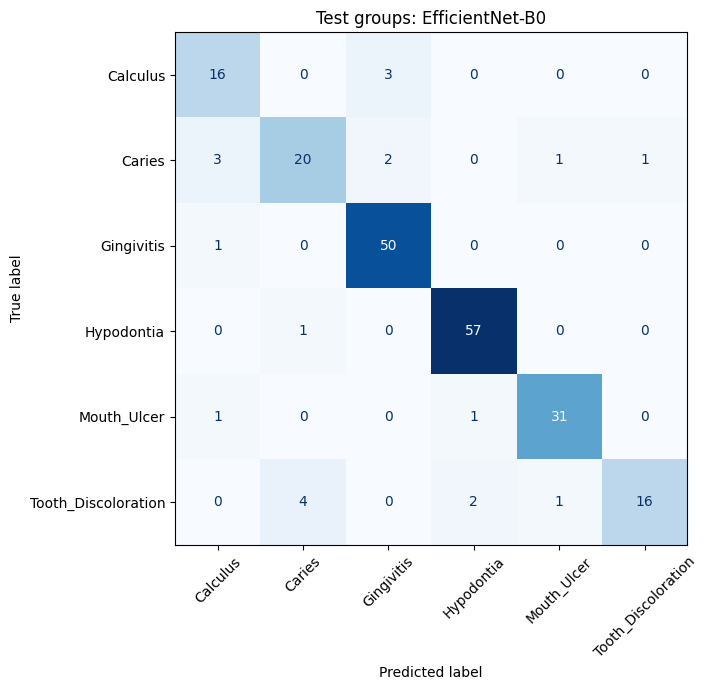

test errors: 21 of 211


In [14]:
fig, axis = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=list(range(len(CLASSES))), display_labels=CLASSES,
    xticks_rotation=45, cmap="Blues", colorbar=False, ax=axis)
axis.set_title(f"Test groups: {MODEL_LABELS[deployment_model_key]}")
plt.tight_layout()
plt.show()
print("test errors:", int((test_predictions != y_test).sum()), "of", len(test))

## 13. Discussion of results
The cell below builds the comparison table and the main observations directly from the results above, so the numbers always match the run.

In [15]:
summary = validation_comparison.merge(test_comparison, on=["model_key", "model"])
display(summary[["model", "val_accuracy", "val_macro_f1", "test_accuracy", "test_macro_f1"]])

best_name = MODEL_LABELS[deployment_model_key]
custom_acc = float(summary.loc[summary["model_key"] == "custom_cnn", "test_accuracy"].iloc[0])
pretrained = summary[summary["model_key"] != "custom_cnn"]
print(f"1) Best model (chosen on validation): {best_name} -> test accuracy {test_accuracy:.3f}, macro-F1 {test_macro_f1:.3f}, "
      f"95% CI {ci_low:.3f}-{ci_high:.3f}.")
print(f"2) Custom CNN trained from scratch: test accuracy {custom_acc:.3f}. The selected model is "
      f"{(test_accuracy - custom_acc) * 100:+.1f} points relative to it (transfer learning from ImageNet vs. learning from limited data).")
print(f"3) Spread between the pretrained models on test accuracy: "
      f"{(pretrained['test_accuracy'].max() - pretrained['test_accuracy'].min()) * 100:.1f} points.")

tuning_spread = (resnet_tuning_table["val_accuracy"].max() - resnet_tuning_table["val_accuracy"].min()) * 100
print(f"4) ResNet50 hyperparameter tuning: validation accuracy ranged over {tuning_spread:.1f} points across 3 trials; "
      f"best config = {best_trial[2]}.")

matrix = confusion_matrix(y_test, test_predictions, labels=list(range(len(CLASSES))))
per_class_recall = matrix.diagonal() / np.maximum(matrix.sum(axis=1), 1)
hardest = int(per_class_recall.argmin())
off_diagonal = matrix.copy()
np.fill_diagonal(off_diagonal, 0)
if off_diagonal.max() > 0:
    a, b = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    print(f"5) Hardest class: {CLASSES[hardest]} (recall {per_class_recall[hardest]:.2f}). "
          f"Most frequent confusion: true {CLASSES[a]} predicted as {CLASSES[b]} ({off_diagonal[a, b]} images).")
else:
    print("5) No misclassified test images.")
print(f"6) Caveat: the test set has only {len(test)} independent images, so differences of a few images between "
      f"models are within the confidence interval. Results are an image-classification aid, not a diagnosis.")

,model,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1
0,EfficientNet-B0,0.938389,0.922426,0.900474,0.869687
1,ResNet50 (tuned),0.928910,0.911841,0.928910,0.912337
2,ConvNeXt-Tiny,0.924171,0.910321,0.914692,0.893127
3,Custom CNN,0.777251,0.741431,0.834123,0.802458


1) Best model (chosen on validation): EfficientNet-B0 -> test accuracy 0.900, macro-F1 0.870, 95% CI 0.858-0.938.
2) Custom CNN trained from scratch: test accuracy 0.834. The selected model is +6.6 points relative to it (transfer learning from ImageNet vs. learning from limited data).
3) Spread between the pretrained models on test accuracy: 2.8 points.
4) ResNet50 hyperparameter tuning: validation accuracy ranged over 4.3 points across 3 trials; best config = {'lr': 0.0003, 'head_lr': 0.0015, 'wd': 0.05, 'ls': 0.1}.
5) Hardest class: Tooth_Discoloration (recall 0.70). Most frequent confusion: true Tooth_Discoloration predicted as Caries (4 images).
6) Caveat: the test set has only 211 independent images, so differences of a few images between models are within the confidence interval. Results are an image-classification aid, not a diagnosis.


## 14. Save the best model
The checkpoint stores the selected network, class order, preprocessing, and evaluation metrics.

In [16]:
CHECKPOINT_PATH = WORKING_DIR / "oral_disease_classifier.pt"
torch.save({
    "model_key": deployment_model_key,
    "model_name": MODEL_LABELS[deployment_model_key],
    "state_dict": copy_state(trained[deployment_model_key]),
    "classes": list(CLASSES),
    "image_size": int(IMG_SIZE),
    "mean": MEAN,
    "std": STD,
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_macro_f1,
}, CHECKPOINT_PATH)
validation_comparison.to_csv(WORKING_DIR / "validation_model_comparison.csv", index=False)
test_comparison.to_csv(WORKING_DIR / "test_model_comparison.csv", index=False)
print("saved:", CHECKPOINT_PATH, "| size MB:", round(os.path.getsize(CHECKPOINT_PATH) / (1024 ** 2), 2))
print(f"total notebook runtime: {(time.time() - T0) / 60:.1f} min")

saved: /kaggle/working/oral_disease_classifier.pt | size MB: 15.59
total notebook runtime: 22.8 min


## 15. Deploy the best model with Gradio
The app loads the saved best model and returns the class probabilities for an uploaded oral image.

In [17]:
try:
    import gradio as gr
except ImportError:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    import gradio as gr

app_checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
app_classes = app_checkpoint["classes"]
app_size = app_checkpoint["image_size"]
app_mean = torch.tensor(app_checkpoint["mean"]).view(1, 3, 1, 1)
app_std = torch.tensor(app_checkpoint["std"]).view(1, 3, 1, 1)

app_model, _ = build_model(app_checkpoint["model_key"], len(app_classes), pretrained=False)
app_model.load_state_dict(app_checkpoint["state_dict"])
app_model = app_model.to(device).eval()

@torch.no_grad()
def predict_oral_image(image):
    if image is None:
        return {}
    image = ImageOps.exif_transpose(image).convert("RGB").resize((app_size, app_size), Image.Resampling.BICUBIC)
    tensor = torch.from_numpy(np.asarray(image, dtype=np.float32) / 255.0).permute(2, 0, 1).unsqueeze(0)
    batch = ((tensor - app_mean) / app_std).to(device)
    probs = F.softmax(app_model(batch).float(), dim=1) + F.softmax(app_model(torch.flip(batch, dims=[3])).float(), dim=1)
    probs = (probs / 2)[0].cpu().numpy()
    return {app_classes[i]: float(probs[i]) for i in range(len(app_classes))}

demo = gr.Interface(
    fn=predict_oral_image,
    inputs=gr.Image(type="pil", label="Oral image"),
    outputs=gr.Label(num_top_classes=len(app_classes), label="Class scores"),
    title="Oral Disease Image Classifier",
    description="Educational image-classification prototype for clinician review.",
)
try:
    demo.launch(share=True, prevent_thread_lock=True)
except Exception as error:
    print("share link unavailable:", error)
    demo.launch(prevent_thread_lock=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://2fbdb590aaed82fb4e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
